In [1]:
!pip install eyepop==3.12.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 69.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 MB 58.8 MB/s  0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: cryptography
    Found existing installation: cryptography 50.0.2
    Uninstalling cryptography-50.0.2:
      Successfully uninstalled cryptography-50.0.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [eyepop]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyopenssl 26.4.0 requires cryptography<51,>=49.0.0, but you have cryptography 46.0.7 which is incompatible.
bigframes 2.51.0 requires pyarrow>=23.0.1, but you have pyarrow 21.0.0 which is incompatible.


In [2]:
import getpass

EYEPOP_ACCOUNT_ID=input("Enter your Account UUID: ")
EYEPOP_API_KEY=getpass.getpass('Enter your API KEY: ')


Enter your Account UUID: a5184defa8e847248f589d35080efbfa
Enter your API KEY: ··········


In [3]:
NAMESPACE_PREFIX="datasciencealliance-org" # Add your namespace-prefix here

# Define Ability

In [4]:
from eyepop import EyePopSdk
from eyepop.data.data_types import InferRuntimeConfig, VlmAbilityGroupCreate, VlmAbilityCreate, TransformInto
from eyepop.worker.worker_types import InferenceComponent, Pop
import json


EMPTY_PARKING_SPOTS_PROMPT = """
Task: Calculate the number of empty parking spots.

Follow this step-by-step method internally:
1. Estimate total lot capacity by counting every painted parking space across all angled and straight rows.
2. Count the total number of physical vehicles parked in stalls (treat cars covered with car covers/tarps as occupied).
3. Subtract occupied vehicles from total capacity (Total Capacity - Occupied Cars = Empty Spots).

Rules:
- Treat all stalls purely as geometrical shapes on the pavement.
- Exclude driving aisles and directional arrows.
- Do not print your work, breakdown, or reasoning.

Output Requirement:
Output ONLY the final calculated integer for the empty spots.
"""


ability_prototypes = [
    VlmAbilityCreate(
        name=f"{NAMESPACE_PREFIX}.describe.empty-parking-spots",
        description="Counting the number of empty parking spots in an image of a parking lot",
        worker_release="qwen3-instruct",
        text_prompt=EMPTY_PARKING_SPOTS_PROMPT,
        transform_into=TransformInto(),
        config=InferRuntimeConfig(
            max_new_tokens=10,
            image_size=1000
        ),
        is_public=False
    )
]

# Create Ability

In [5]:
with EyePopSdk.dataEndpoint(api_key=EYEPOP_API_KEY, account_id=EYEPOP_ACCOUNT_ID) as endpoint:
    for ability_prototype in ability_prototypes:
        ability_group = endpoint.create_vlm_ability_group(VlmAbilityGroupCreate(
            name=ability_prototype.name,
            description=ability_prototype.description,
            default_alias_name=ability_prototype.name,
        ))
        ability = endpoint.create_vlm_ability(
            create=ability_prototype,
            vlm_ability_group_uuid=ability_group.uuid,
        )
        ability = endpoint.publish_vlm_ability(
            vlm_ability_uuid=ability.uuid,
            alias_name=ability_prototype.name,
        )
        ability = endpoint.add_vlm_ability_alias(
            vlm_ability_uuid=ability.uuid,
            alias_name=ability_prototype.name,
            tag_name="latest"
        )
        print(f"created ability {ability.uuid} with alias entries {ability.alias_entries}")

created ability 06adfa620e01783680000a5c28829ae8 with alias entries [AbilityAliasEntry(alias='datasciencealliance-org.describe.empty-parking-spots', tag='1.0.26'), AbilityAliasEntry(alias='datasciencealliance-org.describe.empty-parking-spots', tag='latest')]


# Evaluate on single image

=== INPUT IMAGE ===


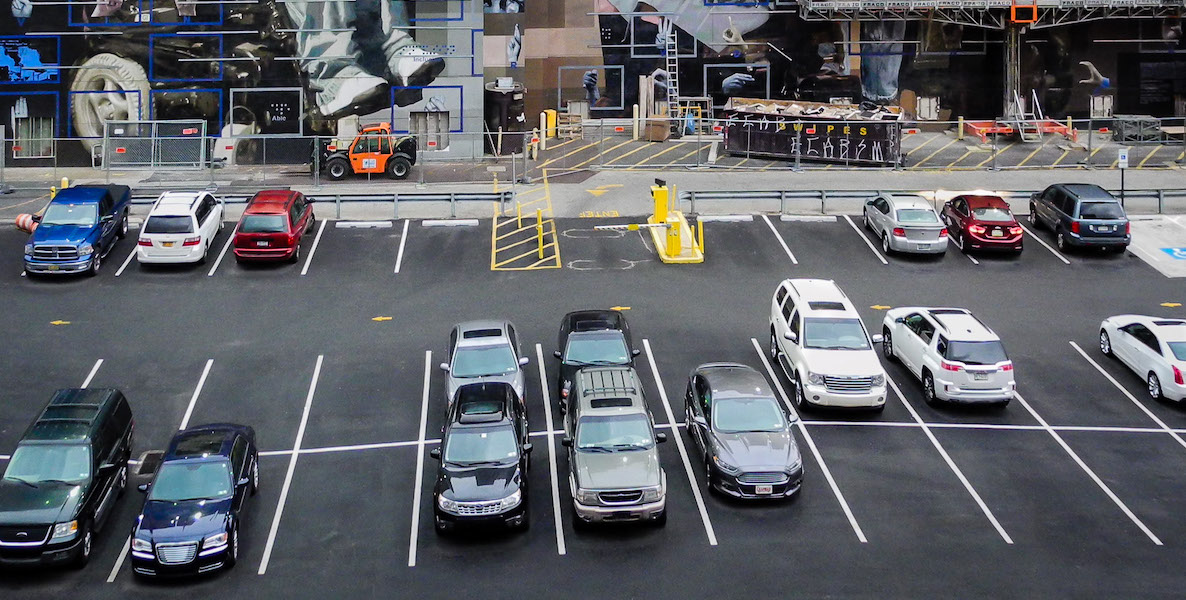


=== EMPTY PARKING SPOTS COUNT ===
14


In [6]:
from pathlib import Path
from PIL import Image
from IPython.display import display

pop = Pop(components=[
    InferenceComponent(
        ability=f"{NAMESPACE_PREFIX}.describe.empty-parking-spots:latest"
    )
])

sample_img_path = Path("/content/parking_lot_image.jpg")

# Display input image
print("=== INPUT IMAGE ===")
display(Image.open(sample_img_path))

# Run inference
with EyePopSdk.workerEndpoint(api_key=EYEPOP_API_KEY) as endpoint:
    endpoint.set_pop(pop)

    job = endpoint.upload(sample_img_path)
    result = job.predict()

# Display prediction
print("\n=== EMPTY PARKING SPOTS COUNT ===")

texts = result.get("texts", [])

if texts:
    for text_item in texts:
        print(text_item.get("text", "").strip())
else:
    print("No prediction returned.")